# Podstawy AI – zbiory rozmyte

**Jedna myśl na całe zajęcia:** ostra granica jest krucha – zmiękczamy ją do stopni. A potem każdy krok, który wydaje się „matematyczny”, okazuje się **decyzją projektową**.


**Jak pracujemy:**
- **✏️** – piszesz kod. Definicje funkcji i operatorów są w prezentacji z wykładu.
- **🧪** – komórka testowa: po uruchomieniu pokaże ✅ albo ❌ z podpowiedzią, co jest nie tak.
- **❓** – odpowiadasz 2–3 zdaniami w komórce pod spodem.

Oddajesz ten notebook.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from functools import reduce


def sprawdz(nazwa, f, przypadki):
    """Testuje funkcję f: przypadki = lista (argumenty, oczekiwany_wynik)."""
    bledy = 0
    for args, oczekiwane in przypadki:
        try:
            wynik = f(*args)
            ok = wynik is not None and np.allclose(np.asarray(wynik, float), oczekiwane, atol=1e-6)
        except Exception as e:
            wynik, ok = f"BŁĄD: {e}", False
        if not ok:
            bledy += 1
            arg = ", ".join(str(np.round(a, 3).tolist()) if isinstance(a, np.ndarray) else str(a) for a in args)
            print(f"{nazwa}({arg}) = {wynik}, oczekiwano {oczekiwane}")
    print(f"{nazwa}: wszystkie testy OK" if bledy == 0 else f"   {nazwa}: {bledy} błędnych przypadków")

---
## Część 1. Funkcje przynależności

### 1.1 Ostra granica vs stopień przynależności

Klasycznie: „wysoka temperatura” to np. **powyżej 25 °C**. Albo tak, albo nie. Rozmyta wersja używa funkcji **γ** z wykładu. Oto jej implementacja – wzoruj się na niej w zadaniu 1.2.

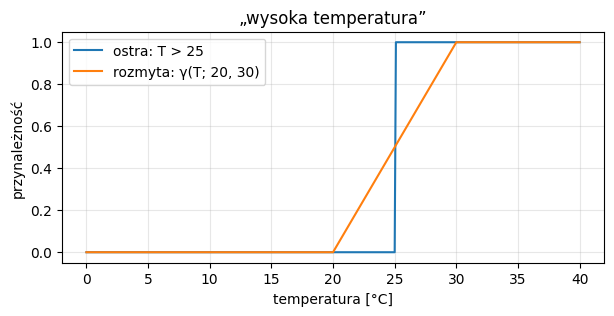

T = 24.9:  ostra = 0,  rozmyta = 0.49
T = 25.1:  ostra = 1,  rozmyta = 0.51


In [3]:
def gamma(x, a, b):
    """Funkcja γ: 0 dla x <= a, liniowo rośnie, 1 dla x >= b. Np. 'wysoki', 'duży'."""
    x = np.asarray(x, dtype=float)
    return np.clip((x - a) / (b - a), 0, 1)


x = np.linspace(0, 40, 401)
plt.figure(figsize=(7, 3))
plt.plot(x, (x > 25).astype(float), label="ostra: T > 25")
plt.plot(x, gamma(x, 20, 30), label="rozmyta: γ(T; 20, 30)")
plt.xlabel("temperatura [°C]"); plt.ylabel("przynależność"); plt.legend(); plt.grid(alpha=.3)
plt.title("„wysoka temperatura”"); plt.show()

for T in (24.9, 25.1):
    print(f"T = {T}:  ostra = {float(T > 25):.0f},  rozmyta = {float(gamma(T, 20, 30)):.2f}")

❓ **1a.** 24,9 °C i 25,1 °C różnią się o 0,2 stopnia. Co z tą różnicą robi definicja ostra, a co rozmyta? Która jest bliższa temu, jak mówią ludzie?

Ostra granica zmienia przynależność z 0 na 1 przy przekroczeniu 25°C, mimo że temperatura zmieniła się zaledwie o 0,2°C. Funkcja rozmyta zmienia wynik łagodnie, z 0,49 na 0,51, dzięki czemu lepiej oddaje potoczne rozumienie pojęcia „wysoka temperatura”.

### 1.2 ✏️ Funkcje L i trójkątna

Zaimplementuj dwie funkcje z wykładu:
- **L(x; a, b)** – 1 dla x ≤ a, liniowo maleje, 0 dla x ≥ b (np. „niski”, „mały”),
- **t(x; a, b, c)** – trójkąt: 0 dla x ≤ a, rośnie do 1 w punkcie b, maleje do 0 w c (np. „średni”).

Funkcje muszą działać zarówno dla pojedynczej liczby, jak i dla całej tablicy `np.array`. Podpowiedź: zobacz, jak zbudowana jest `gamma`. Przydadzą się `np.clip` i `np.minimum`.

In [4]:
def L(x, a, b):
    x = np.asarray(x, dtype=float)
    return np.clip((b - x) / (b - a), 0, 1)


def t(x, a, b, c):
    x = np.asarray(x, dtype=float)
    rosnace = (x - a) / (b - a)
    malejace = (c - x) / (c - b)
    return np.clip(np.minimum(rosnace, malejace), 0, 1)

L: wszystkie testy OK
t: wszystkie testy OK


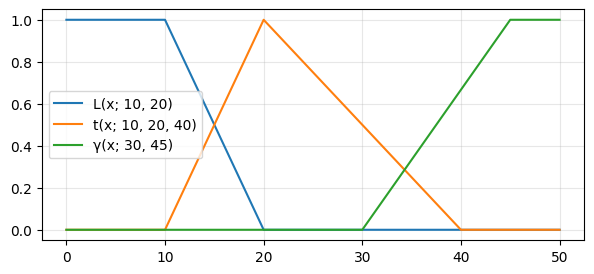

In [5]:
# 🧪 Testy – uruchom bez zmian
sprawdz("L", L, [((0, 10, 20), 1), ((10, 10, 20), 1), ((15, 10, 20), 0.5), ((20, 10, 20), 0), ((30, 10, 20), 0),
                 ((np.array([5, 12.5, 25]), 10, 20), [1, 0.75, 0])])
sprawdz("t", t, [((0, 10, 20, 40), 0), ((15, 10, 20, 40), 0.5), ((20, 10, 20, 40), 1), ((30, 10, 20, 40), 0.5),
                 ((40, 10, 20, 40), 0), ((50, 10, 20, 40), 0), ((np.array([10, 20, 35]), 10, 20, 40), [0, 1, 0.25])])

xx = np.linspace(0, 50, 501)
plt.figure(figsize=(7, 3))
plt.plot(xx, L(xx, 10, 20), label="L(x; 10, 20)")
plt.plot(xx, t(xx, 10, 20, 40), label="t(x; 10, 20, 40)")
plt.plot(xx, gamma(xx, 30, 45), label="γ(x; 30, 45)")
plt.legend(); plt.grid(alpha=.3); plt.show()

### 1.3 ✏️ Prędkość samochodu

Zdefiniuj cztery zbiory na przedziale 0–200 km/h: **mała**, **średnia**, **duża**, **bardzo duża**. Użyj swoich `L`, `t` i `gamma`. Poniższe liczby są celowo złe – popraw je.

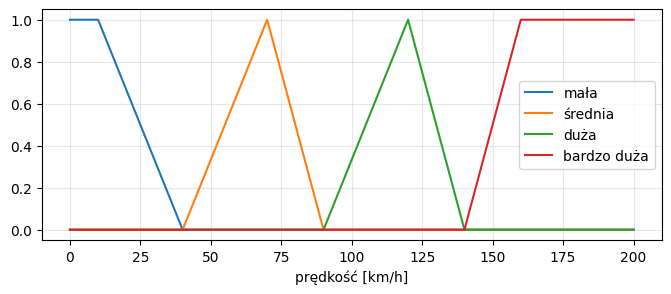

In [6]:
v = np.linspace(0, 200, 401)

#  TODO: popraw parametry
mala        = L(v, 10, 40)
srednia     = t(v, 40, 70, 90)
duza        = t(v, 90, 120, 140)
bardzo_duza = gamma(v, 140, 160)

plt.figure(figsize=(8, 3))
for y, n in [(mala, "mała"), (srednia, "średnia"), (duza, "duża"), (bardzo_duza, "bardzo duża")]:
    plt.plot(v, y, label=n)
plt.xlabel("prędkość [km/h]"); plt.legend(); plt.grid(alpha=.3); plt.show()

❓ **1b.** Dlaczego wybrałeś takie liczby? Czy „duża prędkość” w mieście i na autostradzie to ten sam zbiór?

❓ **1c.** Porównaj swój wykres z osobą obok. Jeśli się różnią – kto ma rację?


1b. Wybrałem te liczby, ponieważ starałem się nie patrzeć na różne sytuacje na drodze (teren zabudowany, ograniczenia, korki, itp.) tylko na najbardziej uniwersalną sytuację, czyli pusta, prosta droga.

1c. Nasze wykresy różniły się od siebie. Nie da się obiektywnie określić kto ma rację, ponieważ każdy postrzega prędkość inaczej, toteż jest to subiektywne odczucie.

### 1.4 ✏️ „Bardzo” i „trochę” (koncentracja i rozcieńczenie)

Zaimplementuj dwie operacje z wykładu: **CON** („bardzo”) i **DIL** („trochę”). Każda to jedna linijka.

In [7]:
def CON(A):
    A = np.power(A, 2)
    return A


def DIL(A):
    A = np.sqrt(A)
    return A

CON: wszystkie testy OK
DIL: wszystkie testy OK


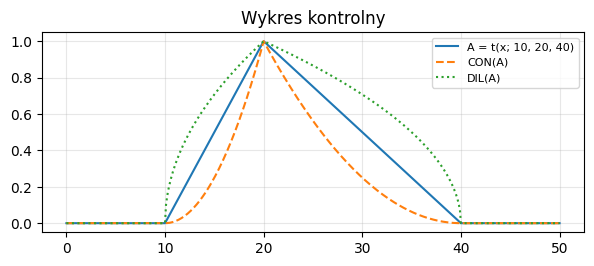

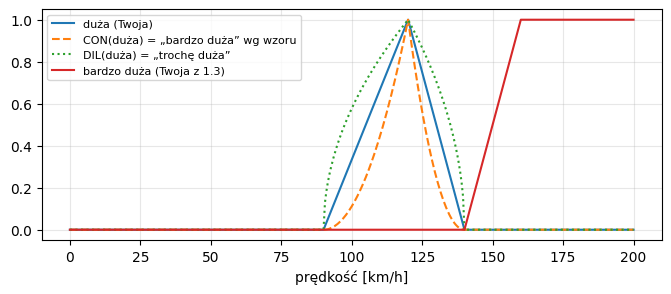

In [8]:
# 🧪 Testy
sprawdz("CON", CON, [((0.5,), 0.25), ((1.0,), 1.0), ((np.array([0, 0.3, 0.9]),), [0, 0.09, 0.81])])
sprawdz("DIL", DIL, [((0.25,), 0.5), ((1.0,), 1.0), ((np.array([0, 0.49, 0.81]),), [0, 0.7, 0.9])])

# Wykres kontrolny – porównaj z prezentacją
xx = np.linspace(0, 50, 501)
A_ = t(xx, 10, 20, 40)
plt.figure(figsize=(7, 2.6))
plt.plot(xx, A_, label="A = t(x; 10, 20, 40)")
plt.plot(xx, CON(A_), "--", label="CON(A)")
plt.plot(xx, DIL(A_), ":", label="DIL(A)")
plt.title("Wykres kontrolny"); plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()

plt.figure(figsize=(8, 3))
plt.plot(v, duza, label="duża (Twoja)")
plt.plot(v, CON(duza), "--", label="CON(duża) = „bardzo duża” wg wzoru")
plt.plot(v, DIL(duza), ":", label="DIL(duża) = „trochę duża”")
plt.plot(v, bardzo_duza, label="bardzo duża (Twoja z 1.3)")
plt.xlabel("prędkość [km/h]"); plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()

❓ **1d.** Porównaj CON(duża) z Twoim zbiorem „bardzo duża”. Czym się różnią kształtem i położeniem? Które lepiej oddaje, co ludzie mają na myśli, mówiąc „bardzo szybko”?

CON(duza) zawęża zbiór poprzez podniesienie stopni przynależności do kwadratu, zachowując maksimum przy 120 km/h. Funkcja gamma z parametrami 140 i 160 przesuwa natomiast przynależność w stronę większych prędkości i osiąga 1 przy 160 km/h. Moim zdaniem gamma lepiej oddaje pojęcie „bardzo szybko”, ponieważ wraz ze wzrostem prędkości stopień przynależności rośnie.

---
## Część 2. Operacje na zbiorach rozmytych

W logice klasycznej „i” to część wspólna, „lub” to suma, „nie” to dopełnienie – i są **jednoznaczne**. W logice rozmytej „i” to dowolna **t-norma**, „lub” to **s-norma**, i jest ich wiele.

### 2.1 ✏️ Implementacja operatorów

Zaimplementuj operatory z wykładu. Wszystkie działają element po elemencie na tablicach (`np.minimum`, `np.maximum`, `np.where` …).

| | „i” (t-norma) | „lub” (s-norma) |
|---|---|---|
| Zadeha | minimum | maksimum |
| algebraiczne | iloczyn | suma probabilistyczna |
| Łukasiewicza | iloczyn ograniczony | suma ograniczona |
| drastyczne | iloczyn drastyczny | suma drastyczna |

oraz negację (dopełnienie).

In [9]:
def NIE(a):
    return 1 - a

# t-normy ("i")
def T_min(a, b):
    return np.minimum(a, b)

def T_iloczyn(a, b):
    return a * b

def T_luk(a, b):          # iloczyn ograniczony (Łukasiewicza)
    return np.maximum(0, a + b - 1)

def T_drast(a, b):        # iloczyn drastyczny
    return np.where(b == 1, a, np.where(a == 1, b, 0))

# s-normy ("lub")
def S_max(a, b):
    return np.maximum(a, b)

def S_prob(a, b):         # suma probabilistyczna
    return a + b - a * b

def S_luk(a, b):          # suma ograniczona (Łukasiewicza)
    return np.minimum(1, a + b)

def S_drast(a, b):        # suma drastyczna
    return np.where(b == 0, a, np.where(a == 0, b, 1))

In [10]:
# Testy
a, b = np.array([0.0, 0.3, 0.6, 1.0, 0.8]), np.array([0.5, 0.9, 0.6, 0.4, 0.0])
sprawdz("NIE",       NIE,       [((a,), [1, 0.7, 0.4, 0, 0.2])])
sprawdz("T_min",     T_min,     [((a, b), [0, 0.3, 0.6, 0.4, 0])])
sprawdz("T_iloczyn", T_iloczyn, [((a, b), [0, 0.27, 0.36, 0.4, 0])])
sprawdz("T_luk",     T_luk,     [((a, b), [0, 0.2, 0.2, 0.4, 0])])
sprawdz("T_drast",   T_drast,   [((a, b), [0, 0, 0, 0.4, 0])])
sprawdz("S_max",     S_max,     [((a, b), [0.5, 0.9, 0.6, 1, 0.8])])
sprawdz("S_prob",    S_prob,    [((a, b), [0.5, 0.93, 0.84, 1, 0.8])])
sprawdz("S_luk",     S_luk,     [((a, b), [0.5, 1, 1, 1, 0.8])])
sprawdz("S_drast",   S_drast,   [((a, b), [0.5, 1, 1, 1, 0.8])])

# Pary (t-norma, s-norma) – przydadzą się dalej
PARY = {
    "Zadeh (min/max)":        (T_min, S_max),
    "algebraiczne":           (T_iloczyn, S_prob),
    "Łukasiewicz":            (T_luk, S_luk),
    "drastyczne":             (T_drast, S_drast),
}

NIE: wszystkie testy OK
T_min: wszystkie testy OK
T_iloczyn: wszystkie testy OK
T_luk: wszystkie testy OK
T_drast: wszystkie testy OK
S_max: wszystkie testy OK
S_prob: wszystkie testy OK
S_luk: wszystkie testy OK
S_drast: wszystkie testy OK


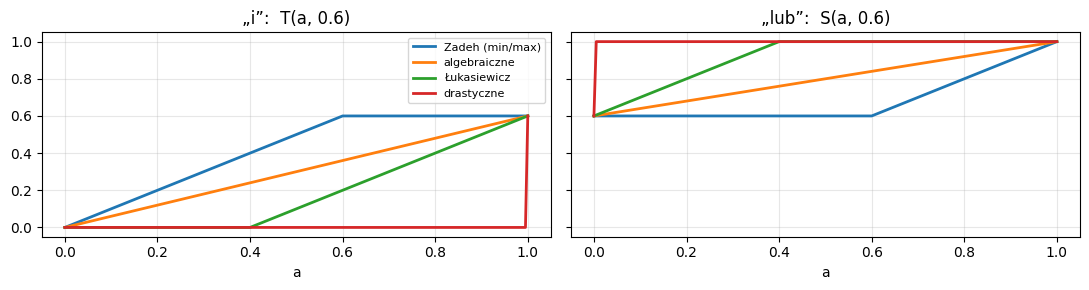

In [11]:
# Wykres kontrolny – porównaj z prezentacją
a_ = np.linspace(0, 1, 201)
b_ = 0.6
fig, osie = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for nazwa, (T, S) in PARY.items():
    osie[0].plot(a_, T(a_, b_), lw=2, label=nazwa)
    osie[1].plot(a_, S(a_, b_), lw=2, label=nazwa)
osie[0].set_title("„i”:  T(a, 0.6)"); osie[1].set_title("„lub”:  S(a, 0.6)")
for o in osie:
    o.set_xlabel("a"); o.grid(alpha=.3)
osie[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### 2.2 Jak wyglądają różne „i”?

Weźmy dwa zbiory: **A = „średnia temperatura”** i **B = „wysoka temperatura”**. Ile prawdy jest w zdaniu „temperatura jest średnia **i** wysoka” – dla każdego operatora?

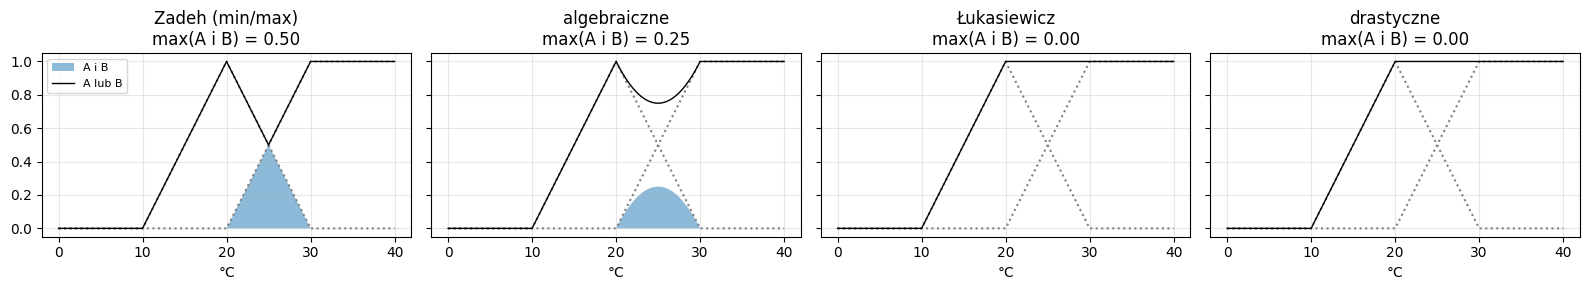

Zadeh (min/max)    S(0.7, 0.7) = 0.70
algebraiczne       S(0.7, 0.7) = 0.91
Łukasiewicz        S(0.7, 0.7) = 1.00
drastyczne         S(0.7, 0.7) = 1.00


In [12]:
x = np.linspace(0, 40, 401)
A_t = t(x, 10, 20, 30)
B_t = gamma(x, 20, 30)

fig, osie = plt.subplots(1, 4, figsize=(16, 3), sharey=True)
for os_, (nazwa, (T, S)) in zip(osie, PARY.items()):
    os_.plot(x, A_t, ":", c="gray"); os_.plot(x, B_t, ":", c="gray")
    os_.fill_between(x, T(A_t, B_t), alpha=.5, label="A i B")
    os_.plot(x, S(A_t, B_t), "k", lw=1, label="A lub B")
    os_.set_title(f"{nazwa}\nmax(A i B) = {np.max(T(A_t, B_t)):.2f}")
    os_.set_xlabel("°C"); os_.grid(alpha=.3)
osie[0].legend(fontsize=8); plt.tight_layout(); plt.show()

# Dwóch niezależnych świadków: każdy jest pewny na 70%, że to był on. „Świadek 1 LUB świadek 2”:
for nazwa, (T, S) in PARY.items():
    print(f"{nazwa:<18} S(0.7, 0.7) = {float(S(0.7, 0.7)):.2f}")

❓ **2a.** Uszereguj cztery „i” od dającego największe wartości do najmniejszych. Przy którym operatorze zdanie „temperatura jest średnia i wysoka” **nigdy** nie jest choć trochę prawdziwe? Czy to rozsądne?




*Twoja odpowiedź:*

Kolejność operatorów t-normy („i”) od dającego największe wartości do najmniejszych:
**Zadeh (min) > algebraiczne (iloczyn) > Łukasiewicz > drastyczne**.

Zdanie „temperatura jest średnia i wysoka” **nigdy** (czyli daje stopień przynależności równy 0 dla każdego $x$) nie jest choć trochę prawdziwe przy **operatorze Łukasiewicza** oraz **operatorze drastycznym** (ich wykresy iloczynu $A \cap B$ leżą całkowicie na osi $y = 0$).

Czy to rozsądne? To zależy od kontekstu projektowego. Z jednej strony intuicyjnie „średnia” i „wysoka” wykluczają się w swoich rdzeniach (dla stopnia 1), jednak na pograniczu (np. przy $25 \text{ } ^\circ\text{C}$) temperatura ma pewien stopień przynależności do obu zbiorów jednocześnie (0.5). Wersja Zadeha lub algebraiczna lepiej oddaje ludzką intuicję, że temperatura $25 \text{ } ^\circ\text{C}$ jest „trochę średnia i trochę wysoka”, podczas gdy Łukasiewicz i operator drastyczny całkowicie odcinają tę łagodną granicę.
```

### 2.3 ✏️ Które prawa logiki przetrwały?

W logice klasycznej (prawda = 1, fałsz = 0) zachodzi pięć praw:

| prawo | zapis | po ludzku |
|---|---|---|
| przemienność | A ∪ B = B ∪ A | kolejność w „lub” nie ma znaczenia |
| idempotentność | A ∩ A = A | „A i A” to po prostu A |
| niesprzeczność | A ∩ ¬A = ∅ | „A i nie-A” jest zawsze fałszem |
| wyłączony środek | A ∪ ¬A = X | „A lub nie-A” jest zawsze prawdą – trzeciej możliwości nie ma |
| de Morgan | ¬(A ∪ B) = ¬A ∩ ¬B | „nie (A lub B)” to „nie A i nie B” |

Czy przetrwają, gdy prawda ma stopnie? Zamiast dowodzić na papierze – sprawdzamy na siatce wszystkich wartości od 0 do 1. Uzupełnij dwa brakujące prawa. Pozostałe są przykładem, jak to zapisać.

In [13]:
siatka = np.linspace(0, 1, 21)
a, b = np.meshgrid(siatka, siatka)       # wszystkie pary (a, b) z siatki

def prawa(T, S):
    return {
        "przemienność A∪B = B∪A":    np.allclose(S(a, b), S(b, a)),
        "idempotentność A∩A = A":    np.allclose(T(a, a), a),
        "niesprzeczność A∩¬A = ∅":   np.allclose(T(a, NIE(a)), 0),
        #  TODO: wyłączony środek A∪¬A = X  (X to zbiór, w którym wszystko ma przynależność 1)
        "wyłączony środek A∪¬A = X": np.allclose(S(a, NIE(a)), 1),
        #  TODO: prawo de Morgana ¬(A∪B) = ¬A ∩ ¬B
        "de Morgan ¬(A∪B) = ¬A∩¬B": np.allclose(NIE(S(a, b)), T(NIE(a), NIE(b)))
    }

wyniki = {nazwa: prawa(T, S) for nazwa, (T, S) in PARY.items()}
print(f"{'prawo':<28}" + "".join(f"{n.split()[0]:>14}" for n in PARY))
for prawo in next(iter(wyniki.values())):
    print(f"{prawo:<28}" + "".join(f"{'✓' if wyniki[n][prawo] else '✗':>14}" for n in PARY))

prawo                                Zadeh  algebraiczne   Łukasiewicz    drastyczne
przemienność A∪B = B∪A                   ✓             ✓             ✓             ✓
idempotentność A∩A = A                   ✓             ✗             ✗             ✗
niesprzeczność A∩¬A = ∅                  ✗             ✗             ✓             ✓
wyłączony środek A∪¬A = X                ✗             ✗             ✓             ✓
de Morgan ¬(A∪B) = ¬A∩¬B                 ✓             ✓             ✓             ✓


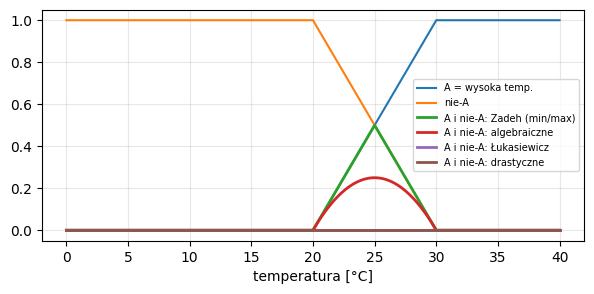

In [14]:
# Jak wygląda „A i nie-A” dla wysokiej temperatury?
A_w = gamma(x, 20, 30)
plt.figure(figsize=(7, 3))
plt.plot(x, A_w, label="A = wysoka temp.")
plt.plot(x, NIE(A_w), label="nie-A")
for nazwa, (T, S) in PARY.items():
    plt.plot(x, T(A_w, NIE(A_w)), lw=2, label=f"A i nie-A: {nazwa}")
plt.xlabel("temperatura [°C]"); plt.legend(fontsize=7); plt.grid(alpha=.3); plt.show()

❓ **2b.** Które prawa logiki klasycznej przetrwały dla każdej pary, a które nie? Czy któraś para zachowuje **wszystkie**?



1. **Prawa, które przetrwały dla wszystkich par:**
   * **Przemienność** ($A \cup B = B \cup A$)
   * **Prawa de Morgana** ($\neg(A \cup B) = \neg A \cap \neg B$)

2. **Prawa, które nie przetrwały dla wszystkich (miały przynajmniej jedno czerwone '✗'):**
   * **Idempotentność** (nie zachodzi dla operatorów algebraicznych, Łukasiewicza i drastycznych).
   * **Niesprzeczność** oraz **wyłączony środek** (nie zachodzą dla operatorów Zadeha i algebraicznych).

3. **Czy któraś para zachowuje wszystkie prawa?**
   * **Nie**, żadna z badanych par operatorów nie zachowuje wszystkich pięciu praw jednocześnie. Pokazuje to podstawową cechę logiki rozmytej – przechodząc na stopnie przynależności, musimy zrezygnować z części klasycznych praw algebraicznych (albo tracimy idempotentność, albo niesprzeczność i wyłączony środek).
```

### 2.4 Wybór uczelni – czy operator zmienia decyzję?

Kandydat dostał się na 4 wydziały. Chce, żeby wydział był **wysoko w rankingu I blisko domu I miał dobrą wymianę I dawał dobre szanse na pracę**. Najpierw zamieniamy liczby na stopnie spełnienia kryteriów – Twoimi funkcjami `L` i `gamma`.

In [15]:
wydzialy = {
    #          miejsce w rankingu, odległość [km], uczelnie partnerskie, zatrudnienie [%]
    "w1": (19, 72, 20, 78),
    "w2": (4,  92, 35, 92),
    "w3": (35, 10, 12, 70),
    "w4": (12, 50,  7, 85),
}

def kryteria(ranking, odleglosc, wymiana, praca):
    return [
        L(ranking, 5, 40),        # 'wysoko w rankingu'
        L(odleglosc, 20, 150),    # 'blisko domu'
        gamma(wymiana, 5, 30),    # 'dobra wymiana'
        gamma(praca, 60, 90),     # 'dobre szanse na pracę'
    ]

stopnie = {w: kryteria(*d) for w, d in wydzialy.items()}
print("        ranking  blisko  wymiana  praca")
for w, s in stopnie.items():
    print(w, "  ", "   ".join(f"{float(x):5.2f}" for x in s))

        ranking  blisko  wymiana  praca
w1     0.60    0.60    0.60    0.60
w2     1.00    0.45    1.00    1.00
w3     0.14    1.00    0.28    0.33
w4     0.80    0.77    0.08    0.83


Teraz łączymy cztery kryteria Twoimi t-normami. `reduce(T, [k1, k2, k3, k4])` liczy T(T(T(k1, k2), k3), k4) – czyli „k1 i k2 i k3 i k4”. Dla porównania dodajemy średnią, która **nie** jest t-normą.

In [16]:
operatory = {nazwa: (lambda T: (lambda s: float(reduce(T, s))))(T) for nazwa, (T, S) in PARY.items()}
operatory["średnia (to NIE „i”)"] = lambda s: float(np.mean(s))

print(f"{'operator':<22}" + "".join(f"{w:>7}" for w in wydzialy) + "   ranking")
for nazwa, op in operatory.items():
    oceny = {w: op(s) for w, s in stopnie.items()}
    kolejnosc = " > ".join(sorted(oceny, key=oceny.get, reverse=True))
    print(f"{nazwa:<22}" + "".join(f"{o:7.2f}" for o in oceny.values()) + "   " + kolejnosc)

operator                   w1     w2     w3     w4   ranking
Zadeh (min/max)          0.60   0.45   0.14   0.08   w1 > w2 > w3 > w4
algebraiczne             0.13   0.45   0.01   0.04   w2 > w1 > w4 > w3
Łukasiewicz              0.00   0.45   0.00   0.00   w2 > w1 > w3 > w4
drastyczne               0.00   0.45   0.00   0.00   w2 > w1 > w3 > w4
średnia (to NIE „i”)     0.60   0.86   0.44   0.62   w2 > w4 > w1 > w3



❓ **2c.** Który wydział wygrywa przy minimum, a który przy iloczynie? Spójrz na tabelę stopni i wyjaśnij, **dlaczego** zwycięzca się zmienia.

Przy operatorze **Zadeh (minimum)** wygrywa wydział **w1** (ocena 0.60), natomiast przy **iloczynie** wygrywa wydział **w2** (ocena 0.45). Zmiana wynika ze specyfiki operatorów: minimum patrzy wyłącznie na najsłabsze kryterium (pesymistyczny strażnik) – dla w1 najsłabsze to 0.60, a dla w2 jest to odległość równa 0.45. Iloczyn z kolei uwzględnia wszystkie oceny: dla w1, mimo równego profilu, wielokrotne mnożenie ułamków drastycznie obniża wynik ($0.6^4 = 0.13$), podczas gdy w2 ma trzy oceny maksymalne (1.0) i jedną 0.45, co daje ostatecznie wyższy wynik ($1 \times 1 \times 1 \times 0.45 = 0.45$).

❓ **2d.** Opisz minimum, iloczyn i Łukasiewicza jednym zdaniem „po ludzku” (np. minimum = „łańcuch jest tak mocny, jak jego najsłabsze ogniwo”). Który z nich najlepiej oddaje to, jak **Ty** wybierałbyś uczelnię?

* **Minimum**: „Łańcuch jest tak mocny, jak jego najsłabsze ogniwo” (całkowity brak kompromisu, liczy się tylko najgorsza cecha).
* **Iloczyn**: „Słabość jednego kryterium można częściowo nadrobić doskonałością innych, ale całkowite niespełnienie choćby jednego i tak zeruje całość”.
* **Łukasiewicz**: „Zbiór twardych wymagań z progiem tolerancji – jeśli masz zbyt wiele drobnych wad lub jedną dużą, to odpadasz całkowicie”.

Do mojego sposobu wyboru uczelni najbardziej pasuje **iloczyn**, ponieważ pozwala docenić wybitne cechy wydziału (np. świetne perspektywy pracy), o ile żadne inne kryterium nie jest całkowicie dyskwalifikujące.

❓ **2f.** Średnia stawia w4 na drugim miejscu, choć wymiana ma tam ocenę 0,08. Dlaczego średnia to nie jest „i”? Kiedy mimo to byłaby rozsądnym wyborem?

Średnia nie jest operatorem typu „i” (t-normą), ponieważ nie spełnia warunku brzegowego t-normy (dla $a=1, b=0$ t-norma musi dać 0, a średnia daje 0.5). Średnia pozwala na pełną kompensację – wybitna ocena z jednego kryterium może całkowicie zamaskować tragiczną ocenę z innego (tak jak świetna praca maskuje brak wymiany międzynarodowej na w4). Średnia byłaby jednak rozsądnym wyborem, gdyby kryteria nie były krytycznymi warunkami koniecznymi, lecz jedynie opcjonalnymi zaletami („miękka koniunkcja”), gdzie zależy nam na ogólnym zrównoważeniu oferty, a nie na bezwzględnym spełnieniu każdego punktu.
```

---
## Część 3. Podsumowanie

❓ **3a.** Wymień trzy miejsca z dzisiejszych zajęć, w których podjąłeś decyzję, którą ktoś inny mógłby rozsądnie podjąć inaczej.

❓ **3b.** Wszystkie liczby w tym notebooku (parametry funkcji, wybór operatora) wpisał człowiek. Jak inaczej można by je uzyskać, gdybyśmy mieli dane?


❓ **3a. Wymień trzy miejsca z dzisiejszych zajęć, w których podjąłeś decyzję, którą ktoś inny mógłby rozsądnie podjąć inaczej.**
1. **Dobór parametrów funkcji przynależności** (Zadanie 1.3): Ktoś mógłby zdefiniować np. „bardzo dużą prędkość” już od 120 km/h (np. pod kątem jazdy w mieście), podczas gdy ja przyjąłem bardziej autostradowe kryteria.
2. **Wybór operatora łączącego kryteria (t-normy)** (Zadanie 2.4): Wybrałem iloczyn jako najbardziej życiowy, ale ktoś bardzo wymagający i bezkompromisowy mógłby uznać, że tylko minimum (Zadeh) gwarantuje brak rozczarowań na studiach.
3. **Sposób modelowania pojęć językowych** (Zadanie 1.4): Zastosowanie matematycznego operatora CON jako potęgi zamiast przesunięcia funkcji w prawo na osi prędkości.

❓ **3b. Wszystkie liczby w tym notebooku (parametry funkcji, wybór operatora) wpisał człowiek. Jak inaczej można by je uzyskać, gdybyśmy mieli dane?**
* **Uczenie maszynowe / optymalizacja parametrów**: Parametry kształtu funkcji przynależności (np. punkty trójkątów $a, b, c$) można dopasować automatycznie za pomocą algorytmów genetycznych lub sieci neuronowych (np. systemy ANFIS) na podstawie historycznych decyzji użytkowników.
* **Statystyka i ankietyzacja**: Granice przedziałów można wyznaczyć statystycznie, pytając liczną grupę ludzi o ich subiektywne oceny (np. od jakiej prędkości uważają jazdę za „bardzo szybką”) i wyciągając średnią/rozkład.
* **Analiza częstotliwościowa danych**: Można użyć algorytmów klastrowania (np. k-średnich) na rzeczywistych danych, aby naturalnie podzielić zakresy (np. prędkości z GPS) na logiczne przedziały i na tej podstawie wygenerować stopnie przynależności.
```